In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square
from mytools.plot import (
    plot_heatmap,
    plot_stack_fit_res,
    plot_axlines,
    plot_line_diff,
    make_figure,
    set_ticks,
    plot_profile_2c,
)
from mytools.estimate import get_signal_level
from crafts_stack.halo_fitting import halofit
from crafts_stack.halo_models import build_model, apply_prior
from astropy.stats import sigma_clip
from mytools.data import read_h5, vitems

In [3]:
data_path = "../data/halo_subtracted_result_pca_halonew_pixweight_squaremask.h5"
vitems(data_path)

Item: crafts_df122k_rmfg0_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_weights
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/res
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10/fit_weights
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df

<Axes: title={'center': 'Weights'}, xlabel='X', ylabel='Y'>

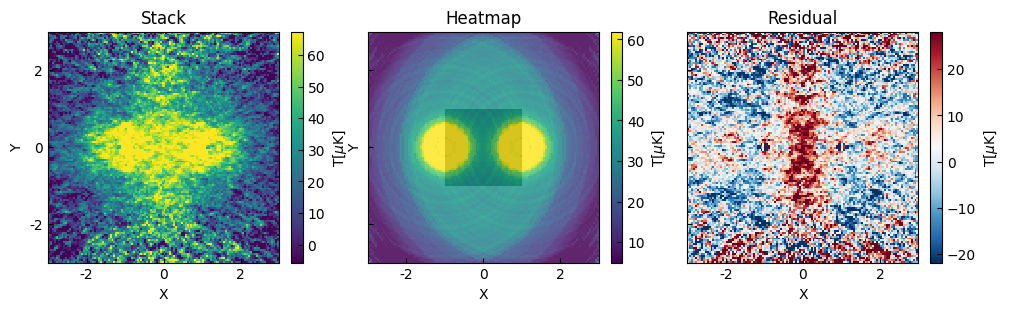

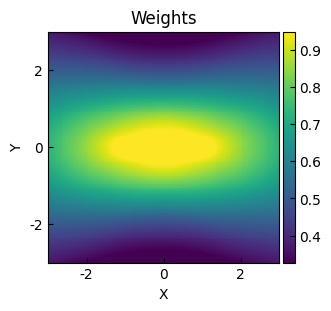

In [4]:
mode = 10
keys = [
    f"crafts_df122k_rmfg{mode}_xsize3000_nfs10/{k}"
    for k in ["stack", "fitted", "fit_weights", "fit_mask"]
]
stack, nfit, weights, mask = read_h5(data_path, keys)
nres = stack - nfit

plot_stack_fit_res(
    [stack, nfit, nres],
    title=["Stack", "Numerical fitting", "Residual"],
    fit_mask=mask,
)
plot_heatmap(weights, title="Weights", cbar_label="")

array([<Axes: title={'center': 'Stack'}, xlabel='X', ylabel='Y'>,
       <Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>,
       <Axes: title={'center': 'Residual'}, xlabel='X'>], dtype=object)

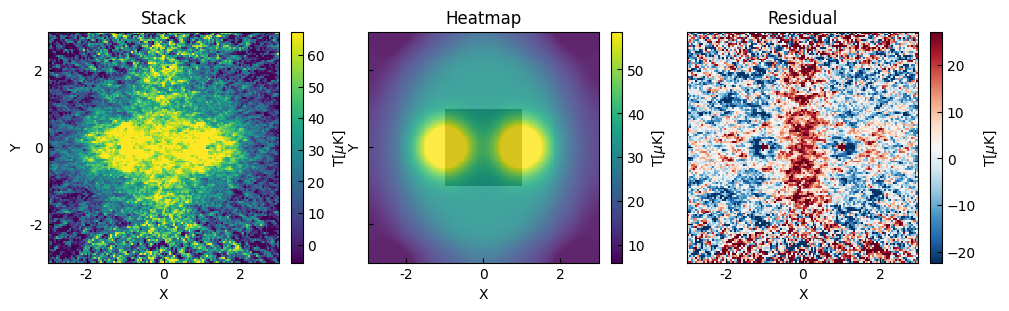

In [5]:
from scipy.ndimage import gaussian_filter
nfit_smooth = gaussian_filter(nfit, sigma=5)
nres_smooth = stack - nfit_smooth
plot_stack_fit_res(
    [stack, nfit_smooth, nres_smooth],
    title=["Stack", "Numerical fitting with smooth", "Residual"],
    fit_mask=mask,
)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(4.566583516371875), np.float64(0.0), np.float64(0.6), np.float64(11.84070434129993)]
Gauss fit covariance: 
[[ 0.13869012  0.00388524 -0.0752256 ]
 [ 0.00388524  0.00462953 -0.01431465]
 [-0.0752256  -0.01431465  0.09198792]]
4 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 5091.416
Reduced chi-squared: 43.516
RMS residual: 6.514

width: 0.6
width_pix: 12


array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

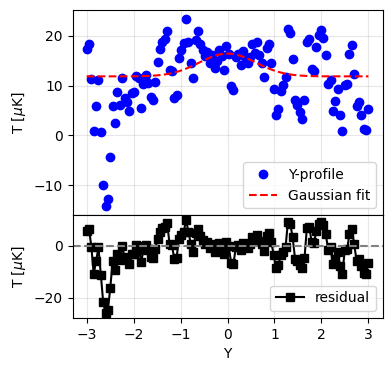

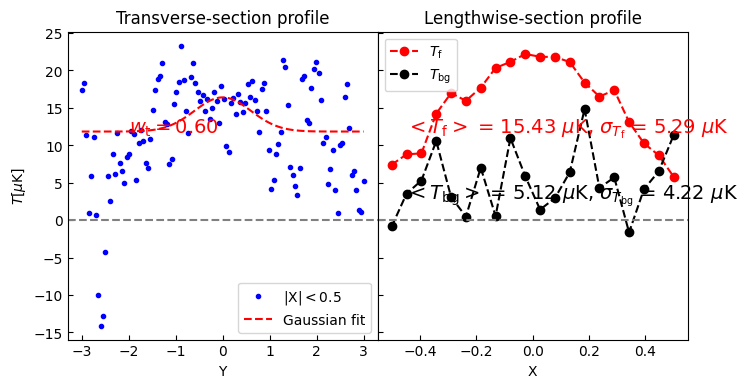

In [12]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.1, 0.6),  # sigma
}

lx, ly, clrb, params, cov = get_signal_level(
    nres_smooth, weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True
)

text_pos = [
    [-0.45, 0.5 * np.max(ly[0])],
    [-0.45, -0.2 * np.min(ly[0])],
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8, 4), wspace=0.0, aspect=None, sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

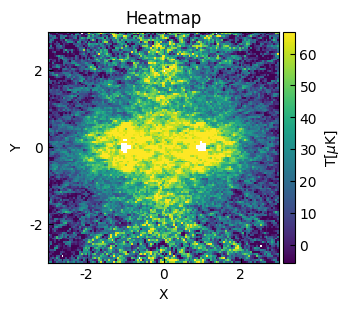

In [13]:
halo_mask = get_mask_sector((0.,0.1), (-np.pi, np.pi))
# mask_stack = np.ma.array(stack, mask=halo_mask)
mask_stack = sigma_clip(stack, 3, maxiters=3, masked=True)
plot_heatmap(mask_stack)

In [14]:
coord = get_coord()

param_bg = {"degree": 2}

model = build_model('nfw', 'poly', param_bg=param_bg)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Polynomial2D(2, c0_0=0., c1_0=0., c2_0=0., c0_1=0., c0_2=0., c1_1=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... c2_0_2 c0_1_2 c0_2_2 c1_1_2
    ----------- -------- -------- ----- ... ------ ------ ------ ------
           50.0     -1.0      0.0   0.5 ...    0.0    0.0    0.0    0.0


In [15]:
bounds = {
    # 'amplitude_0': (0, 200),
    # 'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    "ellipticity_0": (0, 0.5),
    "ellipticity_1": (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    "r_s_0": (0.1, 2),
    "r_s_1": (0.1, 2),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1', 'x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'],
    "fixed": [
        "x_mean_0",
        "y_mean_0",
        "x_mean_1",
        "y_mean_1",
    ],  # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),
        # ('c1_0_2', 'c1_0_3'),
        # ('c2_0_2', 'c2_0_3'),
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ],
}

model = apply_prior(model, bounds=bounds, constraints=constraints)
print(model.fixed)

{'amplitude_0': False, 'x_mean_0': True, 'y_mean_0': True, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': True, 'y_mean_1': True, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'c0_0_2': False, 'c1_0_2': False, 'c2_0_2': False, 'c0_1_2': False, 'c0_2_2': False, 'c1_1_2': False}


<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

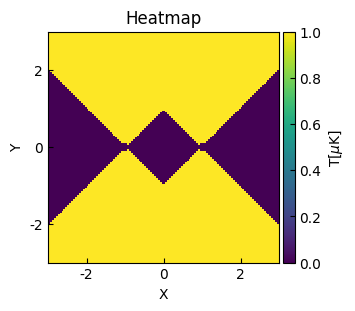

In [16]:
# fit_mask = ~get_mask_square(coord, ylim=(-1,1))
fit_mask = get_mask_sector((0.1,5))
plot_heatmap(fit_mask)

In [17]:
halo_smooth_result, fitted_model, fit_info = halofit(
    coord, mask_stack, model=model, print_model=True, weights=weights[fit_mask], mask=fit_mask
)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=5.9847613, x_mean=-1., y_mean=0., r_s=2., ellipticity=0., theta=174.00842268)>

    [1]: <NFW2D(amplitude=5.9847613, x_mean=1., y_mean=0., r_s=2., ellipticity=0., theta=-185.09971773)>

    [2]: <Polynomial2D(2, c0_0=39.62980367, c1_0=0.28499542, c2_0=-4.86201926, c0_1=-0.13213888, c0_2=-1.17748001, c1_1=-0.00003474)>
Parameters:
       amplitude_0    x_mean_0 ...        c0_2_2                c1_1_2        
    ----------------- -------- ... ------------------- -----------------------
    5.984761303811111     -1.0 ... -1.1774800116644661 -3.4741828683461754e-05

Goodness of fit:
Chi-squared: 2597502.182
Reduced chi-squared: 251.452
RMS residual: 15.853



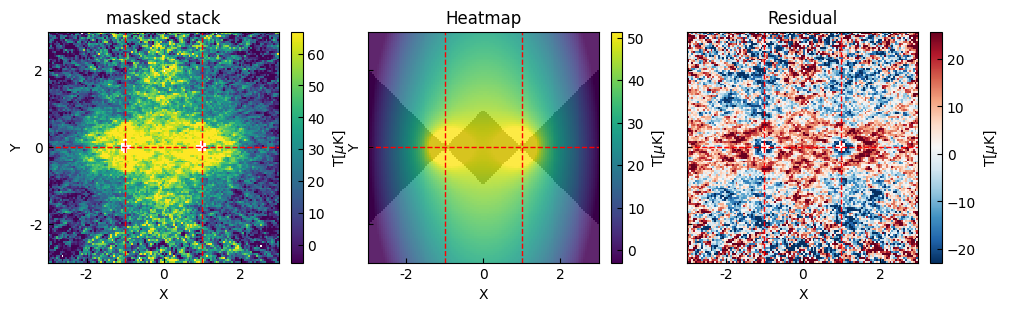

In [18]:
title = ["masked stack", "NFW model fitting", "Residual"]
axes = plot_stack_fit_res(
    halo_smooth_result, title=title, fit_mask=fit_mask
)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# profiles

In [19]:
get_yprofile = lambda dlist, ind: [x[ind, :] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:, ind] for x in dlist]

lines_list = [
    get_yprofile(halo_smooth_result[:2], 60),
    get_xprofile(halo_smooth_result[:2], 40),
    get_xprofile(halo_smooth_result[:2], 80),
]
title_list = ["Y=0", "X=-1", "X=1"]

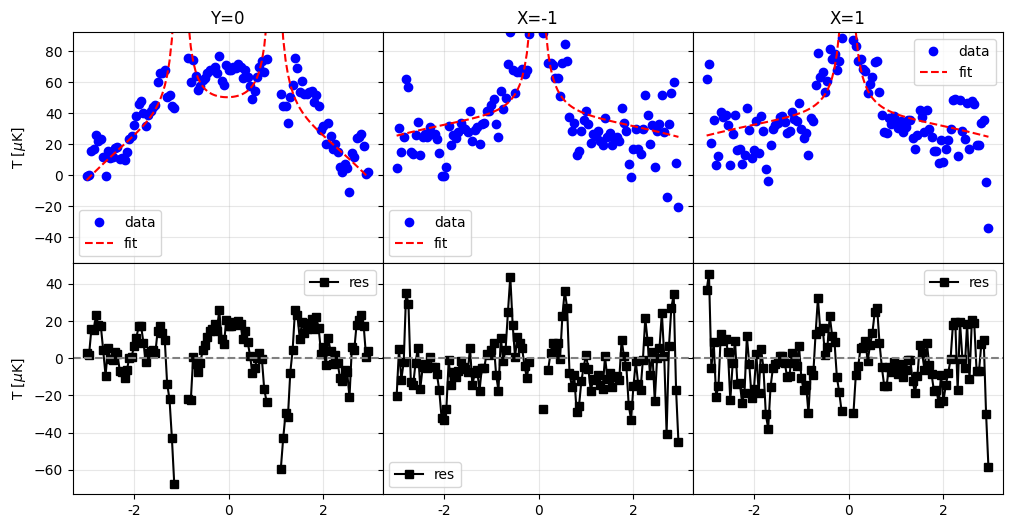

In [20]:
fig, axes = make_figure(
    2,
    3,
    figsize=(12, 6),
    wspace=0.0,
    hspace=0.0,
    aspect=None,
    sharex=True,
    sharey="row",
)

for i, lines in enumerate(lines_list):
    _axes = [axes[0, i], axes[1, i]]

    plot_line_diff(
        *lines, title=title_list[i], axes=_axes, labels=["data", "fit", "res"]
    )

axes[0, 0].set_ylim(ymax=mask_stack.max())
# axes[1, 0].set_ylim(ymin=-100)
axes[0, 0].set_ylabel(r"T [$\mu$K]")
axes[1, 0].set_ylabel(r"T [$\mu$K]")
set_ticks(axes[1, 0], share=False)

# estimate signal level

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(11.050490709528257), np.float64(0.0), np.float64(0.6), np.float64(2.754532422906258)]
Gauss fit covariance: 
[[ 4.9282956   0.2330961  -5.19315606]
 [ 0.2330961   0.01203598 -0.25368647]
 [-5.19315606 -0.25368647  5.56155004]]
3 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 4456.716
Reduced chi-squared: 38.092
RMS residual: 6.094

width: 0.6
width_pix: 12


/home/dyliu/miniconda3/envs/astro/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:867: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


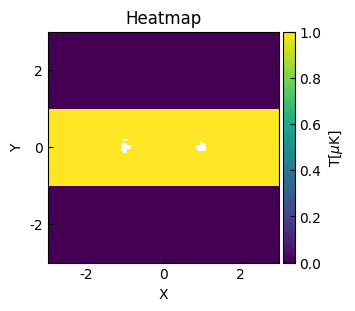

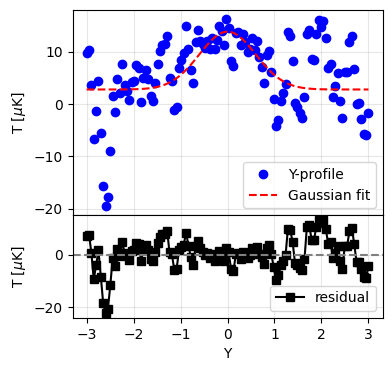

In [23]:
res = halo_smooth_result[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
focus_weight = np.ones_like(res)
# focus_weight[focus_weight<0.7] = 0
focus_weight[:40] = 0
focus_weight[80:] = 0
plot_heatmap(focus_weight)

bounds = {
    "amplitude_0": (0, np.inf),  # amp > 0
    "stddev_0": (0.1, 0.6),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(
    res, weights=focus_weight, bounds=bounds, sigma_clip_sigma=3, show_fit=True
)
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

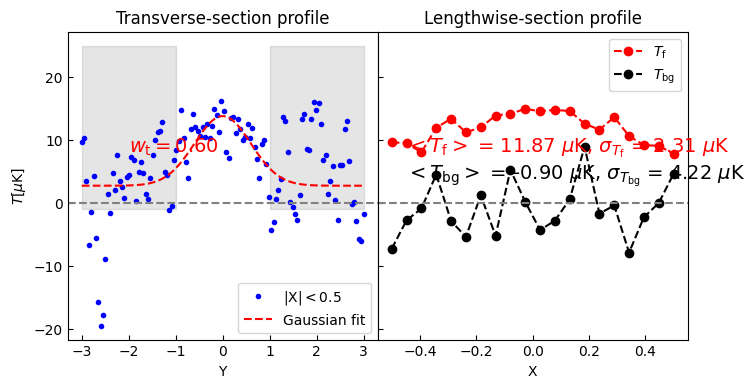

In [24]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])],
    [-0.45, -0.2 * np.min(ly[0])],
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8, 4), wspace=0.0, aspect=None, sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)
axes[0].fill_betweenx([-1, 25], -3, -1, color="k", alpha=0.1)
axes[0].fill_betweenx([-1, 25], 1, 3, color="k", alpha=0.1)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

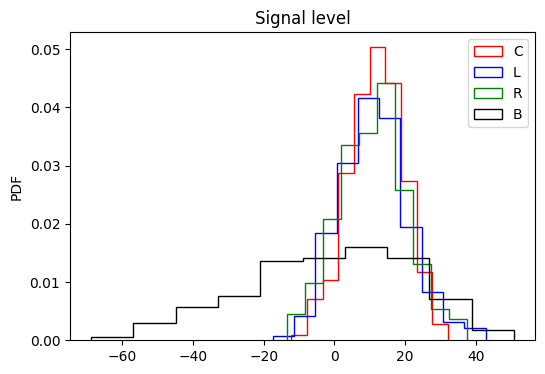

In [25]:

plot_hist(
    clrb, label=["C", "L", "R", "B"], color=["r", "b", "g", "k"], title="Signal level"
)